# La Ciudad que cambió de ritmo
### Evolución del comportamiento del conductor porteño (2019–2025)

**Santiago Minoyetti** · Proyecto 1 — ITBA · Dataset base: flujo vehicular por radares (AUSA / GCBA)

---

**Tesis central:** *La pandemia no solo vació las autopistas: reconfiguró de forma permanente* ***cuándo*** *se mueve la Ciudad. El tránsito volvió en volumen, pero perdió su forma rígida.*

Este notebook ejecuta el **Paso #1 del plan de storytelling**: construye el panel estable de radares, la métrica relativa y los índices base 2019=100, y produce los visuales del **núcleo irrenunciable (Actos 1–3)**. Los Actos 4–5 requieren capas de contexto externas (nafta, SUBE, siniestros) y quedan documentados al final con los extractos listos para cruzar.

**Decisión metodológica clave** — *comparar peras con peras*: la cantidad de radares y autopistas cambia año a año (4 autopistas en 2019, 9 en 2025). Los totales absolutos **no** son comparables. Por eso usamos:
1. **Panel estable**: solo radares/autopistas presentes en los 7 años.
2. **Métrica relativa**: vehículos promedio por radar-hora (no la suma cruda).
3. **Índice base 2019 = 100**: para que toda serie dialogue en un mismo eje.

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 115
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

BASE = Path(r'C:\Users\santi\OneDrive\Documents\itba\Proyecto1')
SRC  = BASE / 'flujo-vehicular-limpio.csv'
OUT  = BASE / 'tableau_extracts'
OUT.mkdir(exist_ok=True)

DIAS = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']
ACCENT = '#c0392b'   # rojo para anotaciones / hitos
BLUE   = '#2c6fbb'
print('Salida de extractos:', OUT)

Salida de extractos: C:\Users\santi\OneDrive\Documents\itba\Proyecto1\tableau_extracts


In [2]:
df = pd.read_csv(SRC, parse_dates=['fecha'], low_memory=False)
df['dow']   = df['fecha'].dt.dayofweek      # 0=Lun ... 6=Dom
df['mes']   = df['fecha'].dt.month
df['anio']  = df['fecha'].dt.year
print(f'{len(df):,} filas · {df.anio.min()}–{df.anio.max()}')
df.head(3)

1,895,607 filas · 2019–2025


,fecha,anio,hora,autopista_nombre,disp_nombre,disp_ubicacion,seccion_sentido,lat,long,cantidad,dow,mes
0,2019-01-01,2019,0.0,AU 4 Lugones,RD165 Dorrego,4.74,A,-34.56336,-58.41529,618.0,1,1
1,2019-01-01,2019,0.0,AU 4 Lugones,RD166 Ombues,5.50,A,-34.56044,-58.41908,797.0,1,1
2,2019-01-01,2019,0.0,AU 4 Lugones,RD168 Juramento,7.20,A,-34.54977,-58.43602,66.0,1,1


## 1. Construcción del panel estable y la métrica relativa

Un radar/autopista entra al panel estable solo si aparece en **los 7 años**. Sobre ese subconjunto, la métrica protagonista es **vehículos promedio por radar-hora**: neutraliza por completo el sesgo de sensores nuevos.

In [3]:
n_anios = df['anio'].nunique()

# Autopistas y radares presentes en todos los años
au_estables = df.groupby('autopista_nombre')['anio'].nunique()
au_estables = au_estables[au_estables == n_anios].index.tolist()

rd_estables = df.groupby('disp_nombre')['anio'].nunique()
rd_estables = rd_estables[rd_estables == n_anios].index.tolist()

panel = df[df['autopista_nombre'].isin(au_estables) &
           df['disp_nombre'].isin(rd_estables)].copy()

print(f'Autopistas estables ({len(au_estables)}): {au_estables}')
print(f'Radares estables: {len(rd_estables)} de {df.disp_nombre.nunique()}')
print(f'Filas en panel estable: {len(panel):,} '
      f'({len(panel)/len(df)*100:.0f}% del total)')

Autopistas estables (4): ['AU 4 Lugones', 'AU 5 Cantilo', 'AU 9 de Julio Sur', 'AU Dellepiane']
Radares estables: 22 de 63
Filas en panel estable: 1,317,863 (70% del total)


In [4]:
# Métrica relativa: vehículos promedio por radar-hora.
# Cada fila YA es un (radar, fecha, hora), así que el promedio simple de
# 'cantidad' sobre un conjunto de filas = vehículos por radar-hora de ese conjunto.
def veh_por_radar_hora(g):
    return g['cantidad'].mean()

anual = panel.groupby('anio').apply(veh_por_radar_hora).rename('veh_radar_hora')
anual_idx = (anual / anual.loc[2019] * 100).rename('indice_base2019')
resumen = pd.concat([anual, anual_idx], axis=1)
resumen

C:\Users\santi\AppData\Local\Temp\ipykernel_13972\72423462.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  anual = panel.groupby('anio').apply(veh_por_radar_hora).rename('veh_radar_hora')


,veh_radar_hora,indice_base2019
anio,,
2019,3012.666171,100.000000
2020,1988.794616,66.014437
2021,2540.834883,84.338415
2022,1616.441019,53.654834
2023,3095.881910,102.762196
2024,3004.501352,99.728984
2025,2734.464158,90.765588


---
## Acto 1 · El pulso normal (2019)
*Presentar al protagonista en su rutina para que el golpe del Acto 2 se sienta.*

### 1.a ¿Cómo latía la Ciudad antes de la pandemia? — Heatmap hora × día

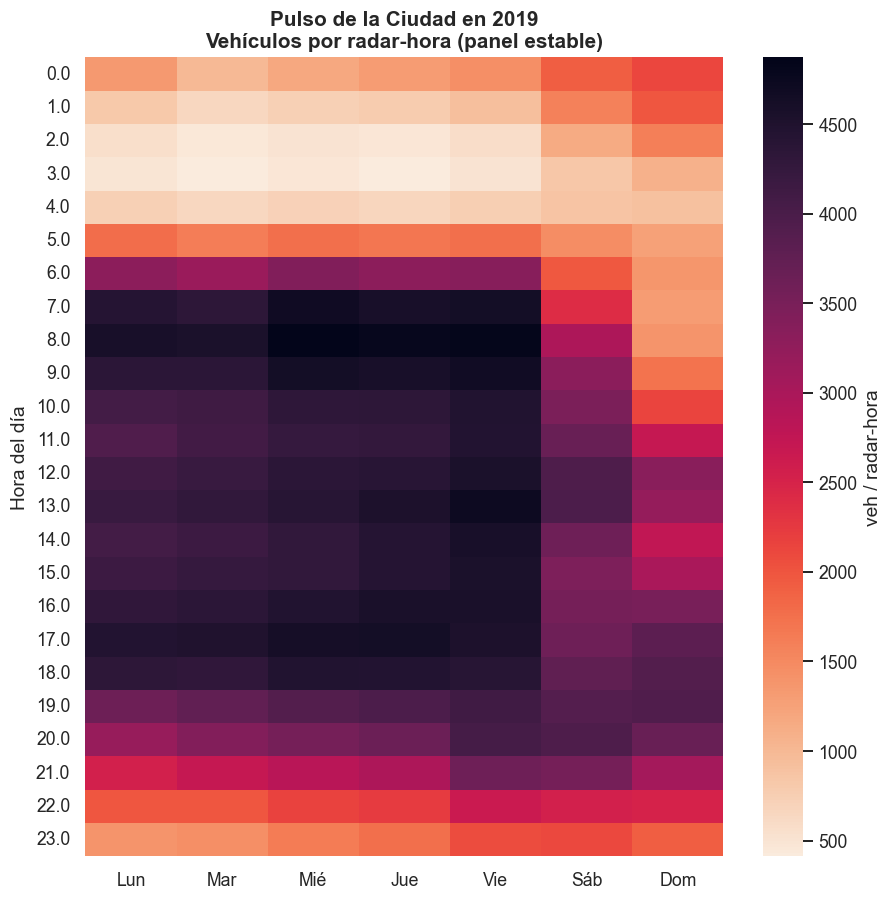

In [5]:
p2019 = panel[panel['anio'] == 2019]
heat = p2019.pivot_table(index='hora', columns='dow', values='cantidad', aggfunc='mean')
heat.columns = DIAS

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(heat, cmap='rocket_r', ax=ax, cbar_kws={'label': 'veh / radar-hora'})
ax.set_title('Pulso de la Ciudad en 2019\nVehículos por radar-hora (panel estable)')
ax.set_xlabel(''); ax.set_ylabel('Hora del día')
plt.tight_layout(); plt.show()

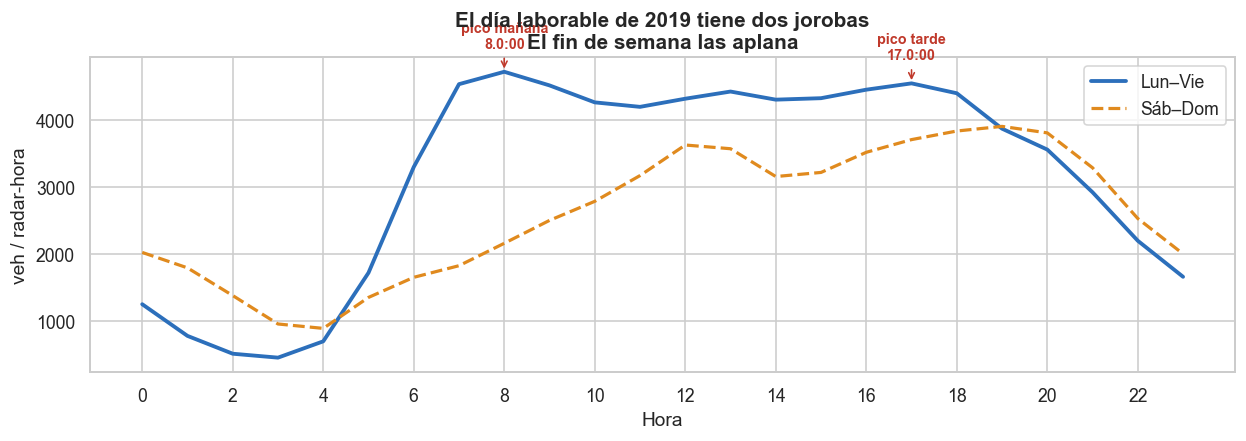

In [6]:
# Serie diaria 2019 con las dos jorobas de hora pico (día laborable típico)
perfil_lab = p2019[p2019['dow'] < 5].groupby('hora')['cantidad'].mean()
perfil_fde = p2019[p2019['dow'] >= 5].groupby('hora')['cantidad'].mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(perfil_lab.index, perfil_lab.values, lw=2.4, color=BLUE, label='Lun–Vie')
ax.plot(perfil_fde.index, perfil_fde.values, lw=2.0, color='#e08a1e', ls='--', label='Sáb–Dom')
pico_m = perfil_lab.iloc[6:12].idxmax(); pico_t = perfil_lab.iloc[15:21].idxmax()
for h, txt in [(pico_m, 'pico mañana'), (pico_t, 'pico tarde')]:
    ax.annotate(f'{txt}\n{h}:00', xy=(h, perfil_lab[h]),
                xytext=(h, perfil_lab[h]+350), ha='center', color=ACCENT,
                fontsize=9, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=ACCENT))
ax.set_title('El día laborable de 2019 tiene dos jorobas\nEl fin de semana las aplana')
ax.set_xlabel('Hora'); ax.set_ylabel('veh / radar-hora')
ax.set_xticks(range(0,24,2)); ax.legend()
plt.tight_layout(); plt.show()

### 1.b ¿Quiénes son los corredores principales? — Ranking + mapa

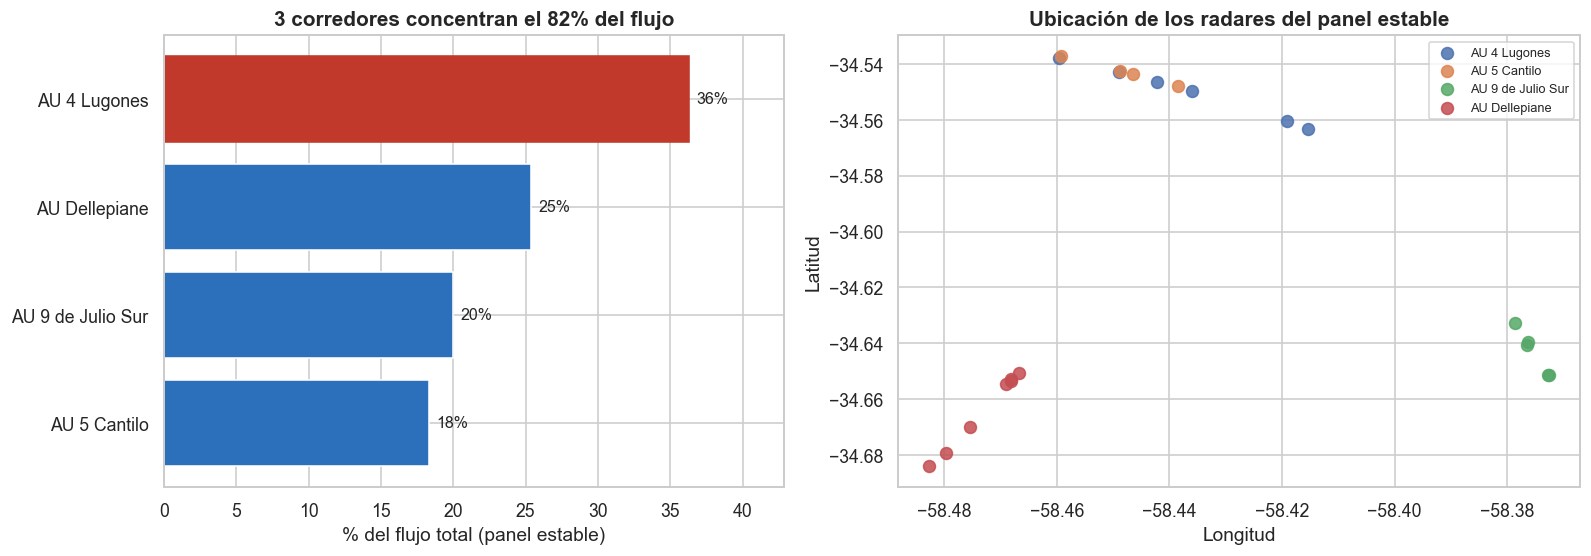

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios':[1,1.1]})

# Ranking por share del flujo (panel estable, todos los años)
share = panel.groupby('autopista_nombre')['cantidad'].sum()
share = (share / share.sum() * 100).sort_values()
bars = axes[0].barh(share.index, share.values, color=BLUE)
bars[-1].set_color(ACCENT)
for i, v in enumerate(share.values):
    axes[0].text(v+0.5, i, f'{v:.0f}%', va='center', fontsize=10)
top3 = share.sort_values(ascending=False).head(3).sum()
axes[0].set_title(f'3 corredores concentran el {top3:.0f}% del flujo')
axes[0].set_xlabel('% del flujo total (panel estable)'); axes[0].set_xlim(0, share.max()*1.18)

# Mapa de radares por lat/long
coords = panel.dropna(subset=['lat','long']).groupby(
    ['disp_nombre','autopista_nombre'])[['lat','long']].first().reset_index()
for au, g in coords.groupby('autopista_nombre'):
    axes[1].scatter(g['long'], g['lat'], s=55, alpha=0.85, label=au)
axes[1].set_title('Ubicación de los radares del panel estable')
axes[1].set_xlabel('Longitud'); axes[1].set_ylabel('Latitud')
axes[1].legend(fontsize=8, loc='best')
plt.tight_layout(); plt.show()

---
## Acto 2 · El shock (2020)
*El derrumbe del ASPO: el momento más dramático del relato.*

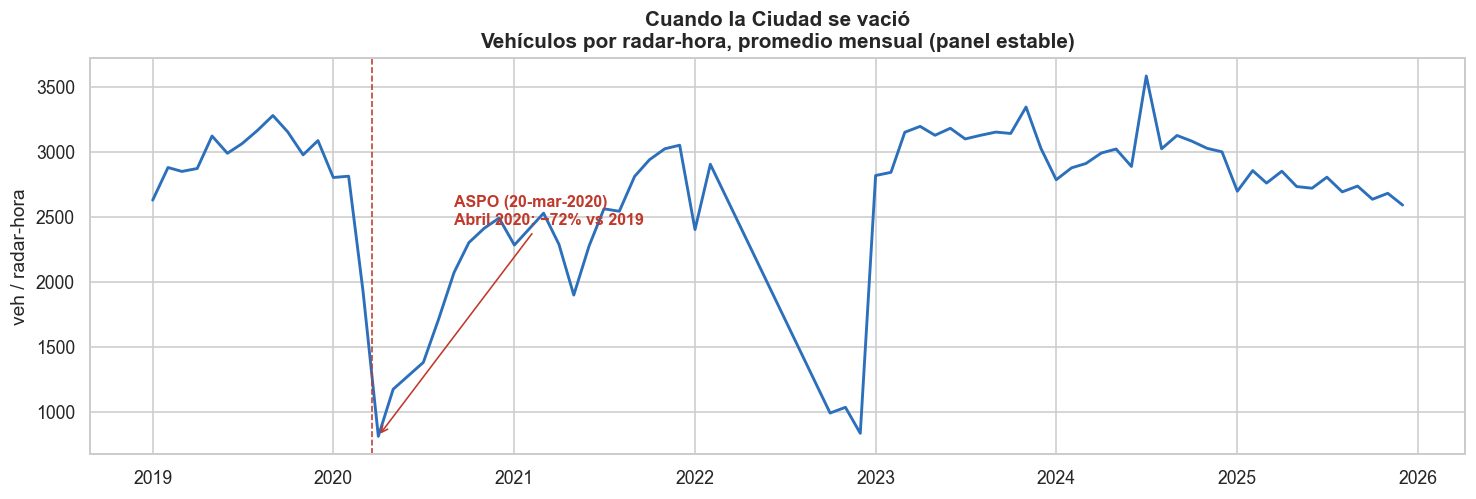

Abril 2019: 2872 · Abril 2020: 809 · Caída: 71.8%


In [8]:
# Serie mensual de veh/radar-hora 2019–2025 con la caída COVID anotada
mensual = panel.groupby([panel['fecha'].dt.to_period('M')])['cantidad'].mean()
mensual.index = mensual.index.to_timestamp()

abr19 = panel[(panel.anio==2019)&(panel.mes==4)]['cantidad'].mean()
abr20 = panel[(panel.anio==2020)&(panel.mes==4)]['cantidad'].mean()
caida = (1 - abr20/abr19) * 100

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(mensual.index, mensual.values, lw=1.8, color=BLUE)
ax.axvline(pd.Timestamp('2020-03-20'), color=ACCENT, ls='--', lw=1)
ax.annotate(f'ASPO (20-mar-2020)\nAbril 2020: −{caida:.0f}% vs 2019',
            xy=(pd.Timestamp('2020-04-01'), abr20),
            xytext=(pd.Timestamp('2020-09-01'), abr19*0.85),
            color=ACCENT, fontweight='bold', fontsize=10,
            arrowprops=dict(arrowstyle='->', color=ACCENT))
ax.set_title('Cuando la Ciudad se vació\nVehículos por radar-hora, promedio mensual (panel estable)')
ax.set_ylabel('veh / radar-hora'); ax.set_xlabel('')
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout(); plt.show()
print(f'Abril 2019: {abr19:.0f} · Abril 2020: {abr20:.0f} · Caída: {caida:.1f}%')

---
## Acto 3 · La recuperación incompleta y el "nuevo normal" (2021–2025)
*La pregunta no es "¿volvió?" sino "¿volvió igual?".*

### 3.a ¿El volumen recuperó su nivel previo? — Índice base 2019=100

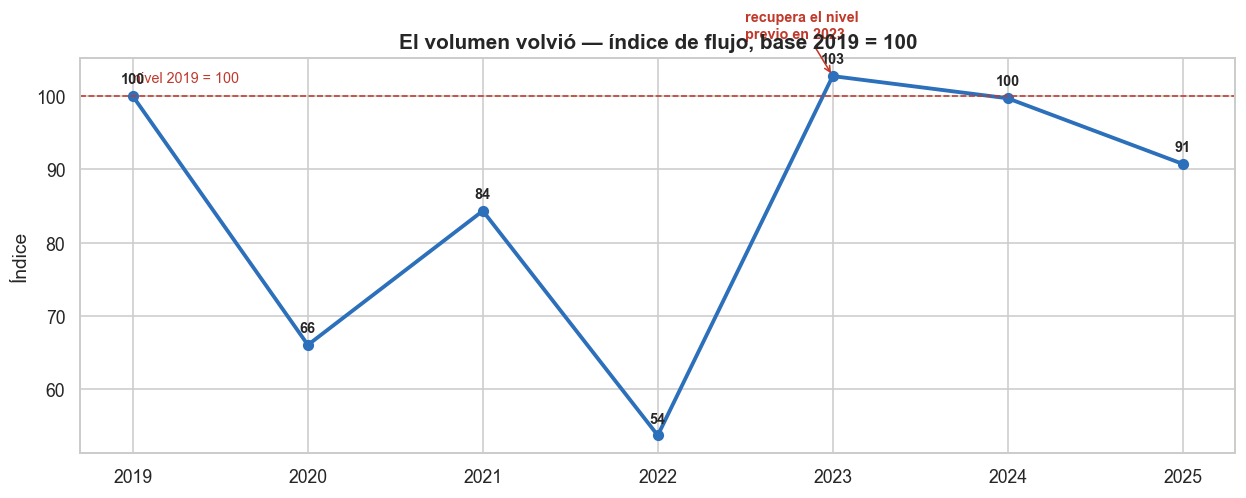

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(anual_idx.index, anual_idx.values, marker='o', lw=2.4, color=BLUE)
ax.axhline(100, color=ACCENT, ls='--', lw=1)
ax.text(anual_idx.index[0], 102, 'nivel 2019 = 100', color=ACCENT, fontsize=9)
for x, y in anual_idx.items():
    ax.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0,8),
                ha='center', fontsize=9, fontweight='bold')
recup = anual_idx[anual_idx >= 100]
if len(recup) > 1:
    yr = recup.index[1] if recup.index[0]==2019 else recup.index[0]
    ax.annotate(f'recupera el nivel\nprevio en {yr}', xy=(yr, anual_idx[yr]),
                xytext=(yr-0.5, 108), color=ACCENT, fontsize=9, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=ACCENT))
ax.set_title('El volumen volvió — índice de flujo, base 2019 = 100')
ax.set_ylabel('Índice'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

### 3.b ¿Cambió la FORMA de la semana y del día? — Perfil pre vs post

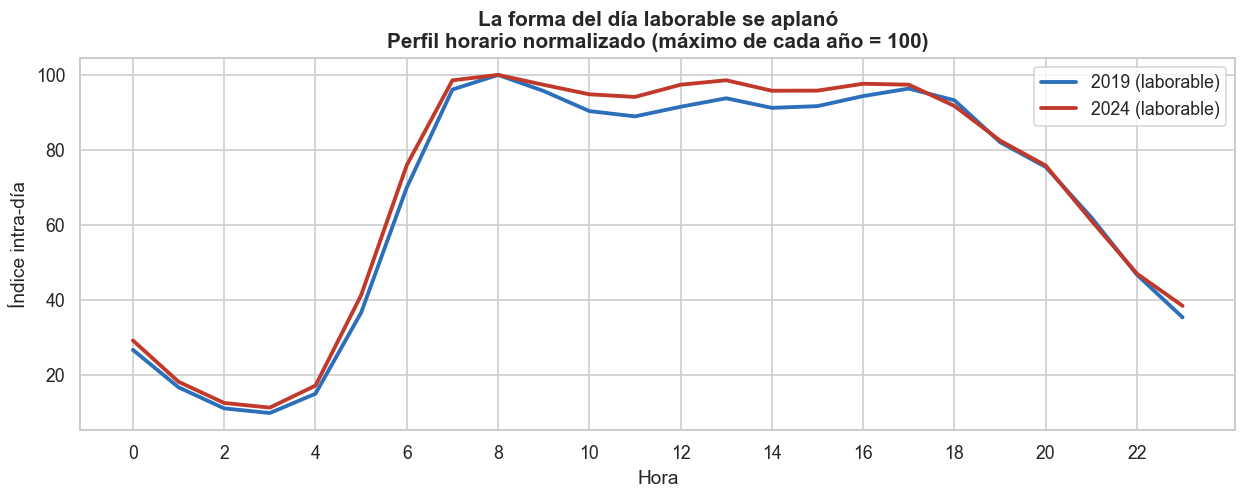

In [10]:
# Perfil horario normalizado (cada año a su propio máximo=100) para comparar FORMA, no nivel
fig, ax = plt.subplots(figsize=(11, 4.5))
for anio, color in [(2019, BLUE), (2024, ACCENT)]:
    perfil = panel[(panel.anio==anio)&(panel.dow<5)].groupby('hora')['cantidad'].mean()
    perfil_n = perfil / perfil.max() * 100
    ax.plot(perfil_n.index, perfil_n.values, lw=2.4, color=color, label=f'{anio} (laborable)')
ax.set_title('La forma del día laborable se aplanó\nPerfil horario normalizado (máximo de cada año = 100)')
ax.set_xlabel('Hora'); ax.set_ylabel('Índice intra-día'); ax.set_xticks(range(0,24,2))
ax.legend()
plt.tight_layout(); plt.show()

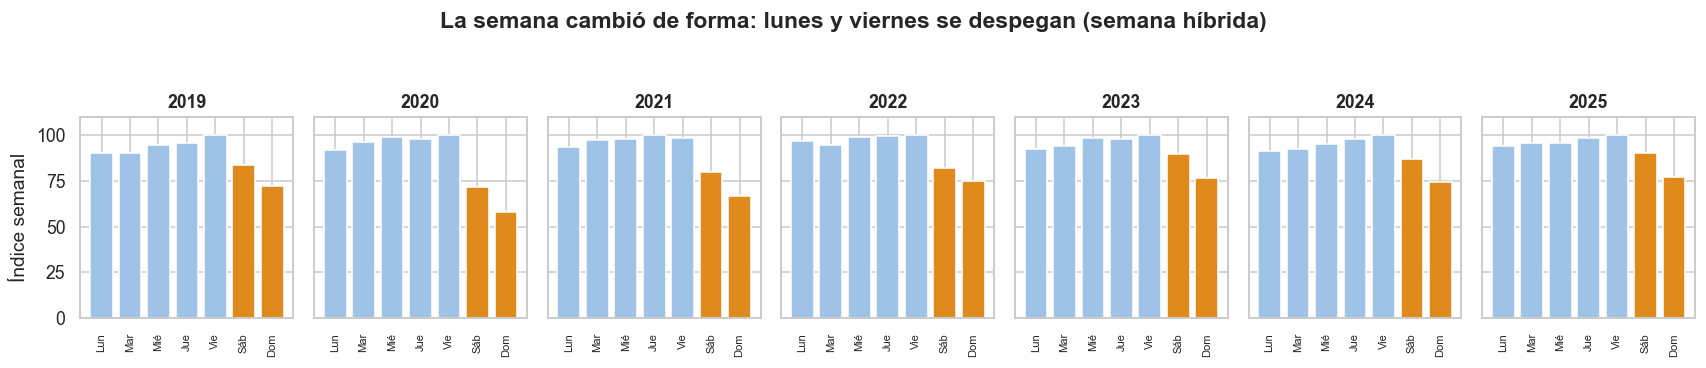

In [11]:
# Small multiples: perfil semanal (día de semana) por año, normalizado
anios = sorted(panel['anio'].unique())
fig, axes = plt.subplots(1, len(anios), figsize=(15, 3), sharey=True)
for ax, anio in zip(axes, anios):
    sem = panel[panel.anio==anio].groupby('dow')['cantidad'].mean()
    sem_n = sem / sem.max() * 100
    colors = ['#9ec3e6']*5 + ['#e08a1e']*2
    ax.bar(range(7), sem_n.values, color=colors)
    ax.set_title(anio, fontsize=11); ax.set_xticks(range(7))
    ax.set_xticklabels(DIAS, rotation=90, fontsize=7); ax.set_ylim(0, 110)
axes[0].set_ylabel('Índice semanal')
fig.suptitle('La semana cambió de forma: lunes y viernes se despegan (semana híbrida)',
             fontweight='bold', y=1.06)
plt.tight_layout(); plt.show()

---
## Exportación de extractos para Tableau
El maquetado final de la *Story* se hace en Tableau. Estos CSV compactos son los que consume cada acto.

In [12]:
# E1 — índice anual base 2019=100 (Acto 3)
resumen.reset_index().to_csv(OUT/'01_indice_anual_base2019.csv', index=False)

# E2 — serie mensual veh/radar-hora (Actos 2 y 3)
mensual.reset_index().rename(columns={'fecha':'mes','cantidad':'veh_radar_hora'}
    ).to_csv(OUT/'02_serie_mensual.csv', index=False)

# E3 — perfil hora × día × año, normalizado y crudo (Actos 1 y 3)
perfil_hda = panel.groupby(['anio','dow','hora'])['cantidad'].mean().reset_index()
perfil_hda['dia'] = perfil_hda['dow'].map(dict(enumerate(DIAS)))
perfil_hda.to_csv(OUT/'03_perfil_hora_dia_anio.csv', index=False)

# E4 — share y coords por autopista (Acto 1)
share.rename('share_pct').reset_index().to_csv(OUT/'04_share_autopistas.csv', index=False)
coords.to_csv(OUT/'05_radares_coords.csv', index=False)

for f in sorted(OUT.glob('*.csv')):
    print(f'  {f.name:38s} {f.stat().st_size/1024:6.1f} KB')

  01_indice_anual_base2019.csv              0.3 KB
  02_serie_mensual.csv                      2.2 KB
  03_perfil_hora_dia_anio.csv              40.3 KB
  04_share_autopistas.csv                   0.2 KB
  05_radares_coords.csv                     1.5 KB


---
## Actos 4–5 · Capas de contexto (pendientes de descarga)

El núcleo (Actos 1–3) queda resuelto **solo con el dataset base**. Los Actos 4 y 5 demuestran la segunda mitad de la tesis (*sensibilidad económica* y *giro de siniestros*) y requieren cruzar capas externas que todavía hay que descargar e indexar:

| Acto | Pregunta | Capa de contexto a sumar | Cómo se cruza con la base |
|------|----------|--------------------------|---------------------------|
| 4 | ¿La nafta frena el tránsito? | Precios en surtidor (Res. 314, Sec. Energía) | Promedio mensual CABA → índice base 2019, doble eje vs `02_serie_mensual` |
| 4 | ¿Sustituyen auto por transporte público? | SUBE transacciones diarias (Min. Transporte) | Índice base 2019, superponer a la serie de flujo; anotar saltos tarifarios |
| 4 | Mundial 2022 | Calendario 7 partidos de Argentina | Zoom horario nov–dic 2022 sobre `03_perfil_hora_dia_anio` |
| 5 | ¿Menos autos → menos víctimas? | Siniestros viales OMSV (GCBA) | Víctimas/mes vs flujo normalizado: ¿sube el riesgo por vehículo cuando baja el volumen? |

**Caveats del dato que el relato debe respetar (heredados de TP3):**
- **2022 incompleto** — faltan ~marzo a septiembre; usar solo tramos publicados y declararlo.
- Comparar siempre **ventanas equivalentes** (mismo rango de meses) entre años.
- El **panel estable** ya mitiga el sesgo de alta/baja de radares.
- Sin **velocidad ni tipo de vehículo**: el relato del riesgo (Acto 5) se apoya en siniestros, no en velocidad medida.